In [1]:
# !pip install torch torchvision matplotlib scikit-learn tqdm pytz
import os
import numpy as np
import torch
from torch import nn
import torch.utils.data as Data
import torchvision
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import pytz
from datetime import datetime

from Algo.get_algos import get_algorithm
from data_util.DataTransformBuilder import build_data_transform
from data_util.DataDistributer import DataPartitioner
from data_util.TinyImageNet_reader import TinyImageNet_reader
from data_util.PACS_reader import Pacs_reader
from data_util.Four_dataset_reader import four_dataset_reader
from Scenario import FL_scenario
from util.TOdevice import to_device
from Models.L2P_heuristic_model import L2P_ViT_B32
from util.saving_tools import load_model_trainable_part


In [2]:
class Args:
    gpus = "0"
    alg = "fedavg"
    dataset = "cifar10"  # ["cifar10","cifar100","PACS","tinyimagenet","fourdataset"]
    device = "cuda" if torch.cuda.is_available() else "cpu"
    n_clients = 80
    batch = 64
    n_sampled_clients = 10
    data_distribution = "non_iid_dirichlet"  # ["non_iid_dirichlet","manual_extreme_heterogeneity"]
    alpha = 0.5
    n_dominated_class = 1
    model_type = "L2P"
    prompt_method = "shallow"
    n_tokens = 4
    dominated_ratio = 0.99
    load_model = None
    instance_label = 1
    # L2P params
    pool_size = 20
    batchwise_prompt = False
    query_model_type = "vit_cls"
    dp_mechanism = "no_dp"  # ["no_dp","Laplace","Gaussian","AnalyticGaussian","Staircase","Prompt"]
    eps = 1.0
    
    # MIA params
    batch_size_mia = 1
    delta_min = 0.02
    delta_max = 0.05
    beta =1 
    

args = Args()
os.environ["CUDA_VISIBLE_DEVICES"] = args.gpus


In [3]:
norm_stats = ((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
resize = 256
centercrop_size = 224
preprocess = build_data_transform(norm_stats, resize, centercrop_size)

class_mask = None
if args.dataset == 'cifar10':
    trainset = torchvision.datasets.CIFAR10(root='./Dataset', train=True, download=True, transform=preprocess)
    testset  = torchvision.datasets.CIFAR10(root='./Dataset', train=False, download=True, transform=preprocess)
    num_classes = 10
elif args.dataset == 'cifar100':
    trainset = torchvision.datasets.CIFAR100(root='./Dataset', train=True, download=True, transform=preprocess)
    testset  = torchvision.datasets.CIFAR100(root='./Dataset', train=False, download=True, transform=preprocess)
    num_classes = 100
elif args.dataset == 'PACS':
    data_name = ['art_painting', 'cartoon', 'photo', 'sketch']
    trainset = [Pacs_reader('./Dataset/PACS', split=d, train=True,  transform=preprocess, random_seed=i) for i, d in enumerate(data_name)]
    testset  = [Pacs_reader('./Dataset/PACS', split=d, train=False, transform=preprocess, random_seed=i) for i, d in enumerate(data_name)]
    testset  = Data.ConcatDataset(testset)
    num_classes = 28
elif args.dataset == 'tinyimagenet':
    trainset = TinyImageNet_reader('./Dataset/tiny-imagenet-200/', train=True,  transform=preprocess)
    testset  = TinyImageNet_reader('./Dataset/tiny-imagenet-200/', train=False, transform=preprocess)
    num_classes = 200
elif args.dataset == 'fourdataset':
    data_name = ['mnistm', 'fashion', 'cinic10', 'mmafedb']
    trainset, class_mask = four_dataset_reader([30000]*4, train=True,  transform=preprocess)
    testset, _          = four_dataset_reader([2500]*4,  train=False, transform=preprocess)
    num_classes = 37
    print(args.dataset)
else:
    raise ValueError("Unsupported dataset")

# global testloader
if args.dataset == 'fourdataset':
    testloader = [Data.DataLoader(testset[i], batch_size=args.batch, num_workers=2, shuffle=False) for i in range(len(testset))]
else:
    testloader = Data.DataLoader(testset, batch_size=args.batch, num_workers=2, shuffle=False)

# data partitioner
if args.dataset in ['PACS', 'fourdataset']:
    data_partitioner = [DataPartitioner(trainset[i], args.n_clients // len(data_name)) for i in range(len(trainset))]
else:
    data_partitioner = DataPartitioner(trainset, args.n_clients)

# alpha→seed mapping (kept as-is)
if args.alpha == 0.01:
    seed = 688
elif args.alpha == 0.05:
    seed = 805
elif args.alpha == 0.1:
    seed = 871
elif args.alpha == 0.2:
    seed = 459
elif args.alpha == 0.3:
    seed = 429
elif args.alpha == 0.4:
    seed = 3760
elif args.alpha == 0.5:
    seed = 448
else: 
    seed = 1234


/home/quannm/.local/lib/python3.11/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


In [4]:
seed = 1234
if args.n_clients > args.n_sampled_clients:
    scenrio_type = 'cross_devices'
else:
    scenrio_type = 'cross_silo'

LATz = pytz.timezone("America/Los_Angeles")
timeInLA = datetime.now(LATz)

if args.data_distribution == 'non_iid_dirichlet':
    if isinstance(data_partitioner, list):
        for i, part in enumerate(data_partitioner):
            if i == 0:
                part.dirichlet_split_noniid(alpha=args.alpha, least_samples=32, manual_seed=seed)
            else:
                part.dirichlet_split_noniid(alpha=args.alpha, least_samples=32, manual_seed=data_partitioner[0].seed)
    else:
        data_partitioner.dirichlet_split_noniid(alpha=args.alpha, least_samples=32, manual_seed=seed)

elif args.data_distribution == 'manual_extreme_heterogeneity':
    if isinstance(data_partitioner, list):
        for part in data_partitioner:
            part.manual_allocating_noniid(args.n_dominated_class, args.dominated_ratio, 1.0)
    else:
        data_partitioner.manual_allocating_noniid(args.n_dominated_class, args.dominated_ratio, 1.0)

    base = f"{args.model_type}_{args.alg}_{args.dataset}_{args.n_clients}clietns_{scenrio_type}_{args.data_distribution}_({args.instance_label})"
else:
    raise ValueError("Unsupported data distribution")



In [5]:
# build FL scenario (unchanged structure)
if args.dataset in ['PACS', 'fourdataset']:
    all_clients_weights = np.concatenate([p.get_all_client_weights() for p in data_partitioner])
    loaders = [p.get_distributed_data(batch_size=args.batch) for p in data_partitioner]
    distributed_dataloaders = [loaders[i][j] for i in range(len(loaders)) for j in range(data_partitioner[i].n_clients)]
    fl_scen = FL_scenario(all_clients_weights, args.n_clients, args.n_sampled_clients, distributed_dataloaders)
else:
    fl_scen = FL_scenario(
        data_partitioner.get_all_client_weights(),
        args.n_clients, args.n_sampled_clients,
        data_partitioner.get_distributed_data(batch_size=args.batch)
    )

# model
if args.model_type != 'L2P':
    raise ValueError("Only L2P path shown here")
if args.query_model_type == 'vit_cls':
    server_model = to_device(
        L2P_ViT_B32(prompt_method=args.prompt_method,
                    batchwise_prompt=args.batchwise_prompt,
                    pool_size=args.pool_size,
                    top_k=args.n_tokens,
                    num_classes=num_classes,
                    candidate_key=None),
        args.device
    )

server_model.build_trainable_keys()

In [6]:
# pick algorithm
associate_algo = args.alg.split('_')[0] if '_' in args.alg else args.alg
algclass = get_algorithm(associate_algo)

if args.alg == 'fedavg_nonpara':
    algo = algclass(server_model=server_model, scenario=fl_scen,
                    loss_fun=nn.CrossEntropyLoss(), fed_method='nonparametric_aggregation',
                    nonpara_hidden=args.nonpara_hidden, class_mask=class_mask, device=args.device)
elif args.alg == 'fedavg':
    algo = algclass(server_model=server_model, scenario=fl_scen,
                    loss_fun=nn.CrossEntropyLoss(), fed_method='aggregation',
                    class_mask=class_mask, device=args.device)
else:
    raise ValueError("Unsupported algorithm")


In [7]:
if args.dataset == 'PACS' or args.dataset == 'fourdataset':
    train_dataloader_list = [torch.utils.data.DataLoader(dataset, batch_size=args.batch_size_mia, shuffle=False) for dataset in trainset]
    test_dataloader_list = [torch.utils.data.DataLoader(dataset, batch_size=args.batch_size_mia, shuffle=False) for dataset in testset]
else:
    train_dataloader_list = [torch.utils.data.DataLoader(trainset, batch_size=args.batch_size_mia, shuffle=False)]
    test_dataloader_list = [torch.utils.data.DataLoader(testset, batch_size=args.batch_size_mia, shuffle=False)]
mia_dataloader_list = train_dataloader_list
mia_dataloader_list_test = test_dataloader_list

In [8]:
import matplotlib.patheffects as pe
args.load_model = '/home/quannm/code/nips-promptmia/output_record/saved_model/saved_model_L2P_fedavg_cifar10_80clietns_cross_devices_modelvit_cls_non_iid_dirichlet_alpha0.5_1_round_61_acc_0.9442.pt'
# args.load_model = None
if args.load_model is not None:
    load_model_trainable_part(algo.server_model, args.load_model)
    print(f"Model loaded from {args.load_model}\n")
# 🔒 snapshot keys once
with torch.no_grad():
    fixed_keys = algo.server_model.pool.key.clone()
    fixed_key_norm_torch = algo.server_model.pool.l2_normalize(fixed_keys, dim=1)
    fixed_key_norm = fixed_key_norm_torch.cpu().numpy()

# pick the dataset (train or test, member or non-member)
dataset = mia_dataloader_list[0].dataset       # e.g., first dataloader (train/member)
dataset_test = mia_dataloader_list_test[0].dataset 




Model loaded from /home/quannm/code/nips-promptmia/output_record/saved_model/saved_model_L2P_fedavg_cifar10_80clietns_cross_devices_modelvit_cls_non_iid_dirichlet_alpha0.5_1_round_61_acc_0.9442.pt



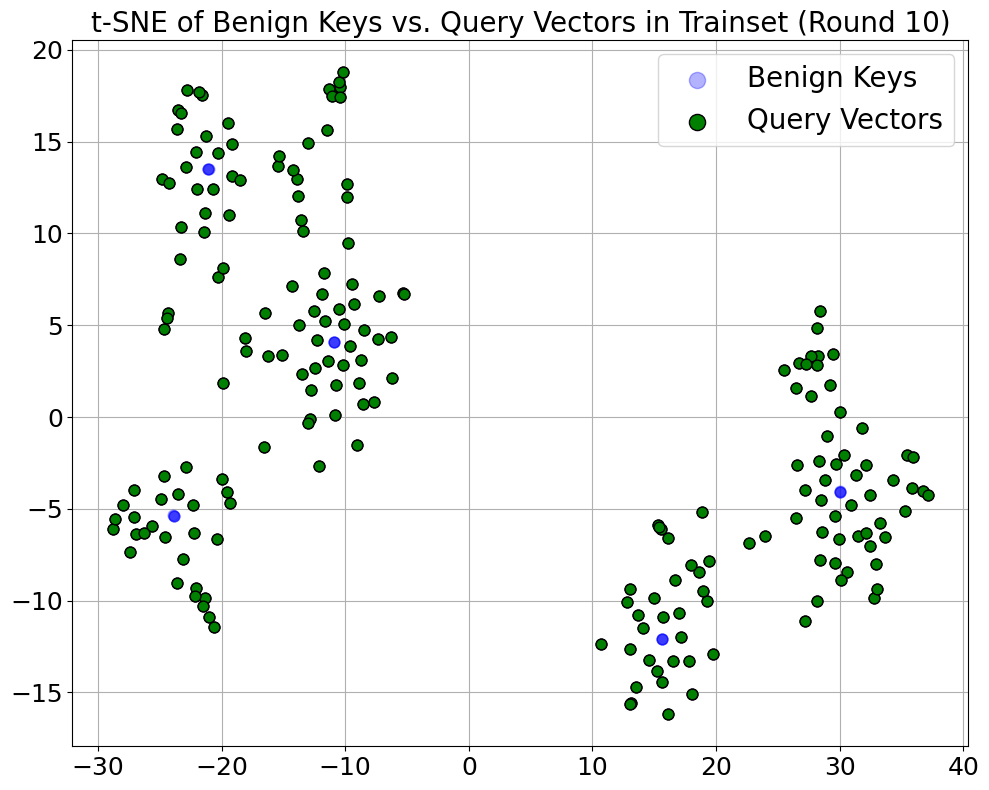

In [9]:
import matplotlib.patheffects as pe
from sklearn.manifold import TSNE

# collect query vectors (first 100 x’s)
query_vectors = []
for sample_id in range(200):
    x, label = dataset[sample_id]
    x = x.unsqueeze(0).to(args.device).float()
    with torch.no_grad():
        feat = algo.server_model.get_cls_keys(x)
        x_embed_norm = algo.client_model[0].pool.l2_normalize(feat, dim=1)
    query_vectors.append(x_embed_norm.detach().cpu().numpy())

query_vectors = np.vstack(query_vectors)   # shape: (100, d)

# combine keys + queries
combined = np.concatenate([fixed_key_norm, query_vectors], axis=0)

# t-SNE
tsne = TSNE(n_components=2, random_state=42, perplexity=10)
tsne_result = tsne.fit_transform(combined)

key_count = len(fixed_key_norm)
plt.figure(figsize=(10, 8))

# keys
plt.scatter(tsne_result[:key_count, 0], tsne_result[:key_count, 1],
            c='blue', alpha=0.3, s=60, label='Benign Keys', zorder=5)

# queries (100 of them)
query_start = key_count
for i in range(200):
    qx, qy = tsne_result[query_start + i]
    plt.scatter(qx, qy, c='green', edgecolors='black', s=60, marker='o', zorder=20)
    # plt.text(qx, qy, f"Q{i}", fontsize=12, ha='center', va='bottom', color='darkgreen',
    #          path_effects=[pe.withStroke(linewidth=2, foreground='white', alpha=0.9)])
plt.scatter(tsne_result[query_start:query_start+40000, 0],
            tsne_result[query_start:query_start+40000, 1],
            c='green', edgecolors='black', s=60, marker='o',
            label='Query Vectors', zorder=20)

plt.title('t-SNE of Benign Keys vs. Query Vectors in Trainset (Round 10)', fontsize=20)
# # --- match previous style ---
# plt.title('t-SNE of Global Keys (with PromptMIA Injected Keys Highlighted)', fontsize=16)
plt.legend(fontsize=20, markerscale=1.5)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.grid(True)
plt.tight_layout()
plt.show()


/tmp/ipykernel_894808/2066084775.py:65: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


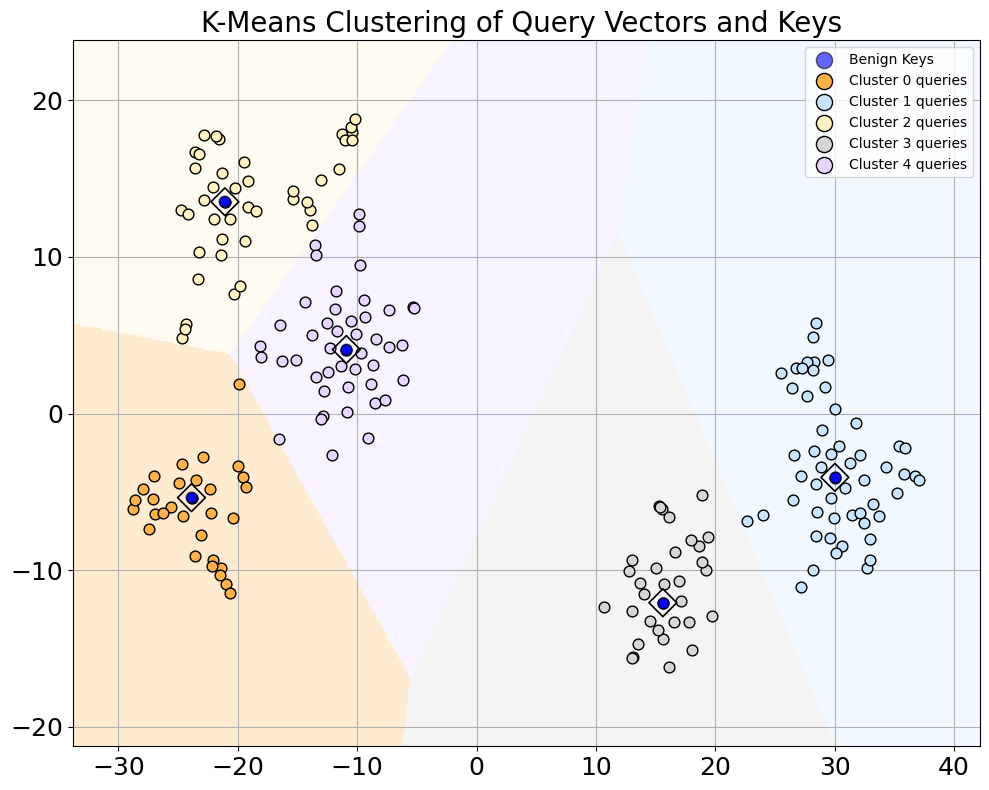

In [10]:
# --- Divide into 5 regions via meta-centroids over keys ---
import numpy as np
from sklearn.cluster import KMeans
from matplotlib.colors import ListedColormap

key_emb   = tsne_result[:key_count]
query_emb = tsne_result[key_count:key_count + 200]

# cluster the keys themselves into 5 super-groups (meta-centroids)
n_regions = min(5, key_count)  # safety if <5 keys
kmeans = KMeans(n_clusters=n_regions, n_init=10, random_state=42)
key_region = kmeans.fit_predict(key_emb)          # region id for each key
centers = kmeans.cluster_centers_                 # (n_regions, 2)

# assign each query to its nearest region center
qdists = ((query_emb[:, None, :] - centers[None, :, :])**2).sum(-1)**0.5
q_region = qdists.argmin(axis=1)

# --- background regions (Voronoi-like shading by region) ---
pad = 5
xmin, ymin = tsne_result.min(axis=0) - pad
xmax, ymax = tsne_result.max(axis=0) + pad
xx, yy = np.meshgrid(np.linspace(xmin, xmax, 500),
                     np.linspace(ymin, ymax, 500))
grid = np.c_[xx.ravel(), yy.ravel()]
gdists = ((grid[:, None, :] - centers[None, :, :])**2).sum(-1)**0.5
gassign = gdists.argmin(axis=1).reshape(xx.shape)

region_cmap = ListedColormap(["#ffb347", "#c9e4ff", "#fff3c4", "#d6d6d6", "#e6d6ff"])
plt.figure(figsize=(10, 8))
# region_cmap = ListedColormap(["#aec6cf", "#ffb347", "#cbaacb", "#ffb6b9", "#d6d6d6"])
plt.pcolormesh(xx, yy, gassign, shading="auto", cmap=region_cmap, alpha=0.25, zorder=0)

# --- plot keys (keep your blue scatter) but also outline their region ---
plt.scatter(key_emb[:, 0], key_emb[:, 1],
            c='blue', alpha=0.6, s=60, label='Benign Keys', zorder=10, edgecolors='black')

# optional: show meta-centers
plt.scatter(centers[:, 0], centers[:, 1],
            c='none', edgecolors='black', s=200, marker='D', linewidths=1.2,
            zorder=12)

# --- plot queries colored by region ---
region_colors = np.array(region_cmap.colors)
for r in range(n_regions):
    mask = (q_region == r)
    if not np.any(mask):
        continue
    plt.scatter(query_emb[mask, 0], query_emb[mask, 1],
                c=[region_colors[r]], marker='o', s=60, edgecolors='black',
                label=f'Cluster {r} queries' if r < 5 else None, zorder=5)

# keep your highlighted Q0 (update to new arrays)
q0x, q0y = query_emb[0]
# plt.scatter(q0x, q0y, c='orange', edgecolors='black', s=120, marker='*',
#             label='Highlighted Q0', zorder=25)

plt.title('K-Means Clustering of Query Vectors and Keys ', fontsize=20)
# # --- match previous style ---
# plt.title('t-SNE of Global Keys (with PromptMIA Injected Keys Highlighted)', fontsize=16)
plt.legend(fontsize=10, markerscale=1.5)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.grid(True)
plt.tight_layout()
plt.show()


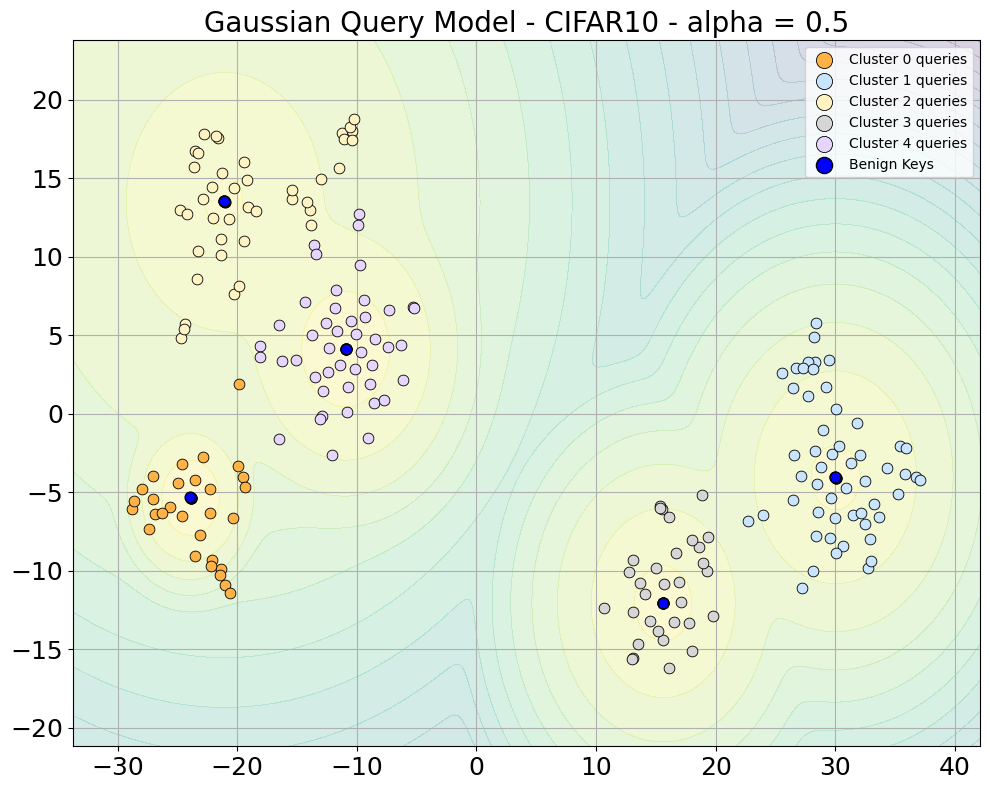

In [11]:
# ===== Region partition + Gaussian overlay + keys on top =====
import numpy as np
from sklearn.cluster import KMeans
from matplotlib.colors import ListedColormap

key_emb   = tsne_result[:key_count]
query_emb = tsne_result[key_count:key_count + 200]
n_regions = min(5, key_count)

# --- cluster keys into 5 meta-centroids (regions) ---
kmeans = KMeans(n_clusters=n_regions, n_init=10, random_state=42)
key_region = kmeans.fit_predict(key_emb)
centers = kmeans.cluster_centers_

# --- assign each query to its nearest region center ---
qdists = ((query_emb[:, None, :] - centers[None, :, :])**2).sum(-1)**0.5
q_region = qdists.argmin(axis=1)

# --- background regions (Voronoi-like shading by region) ---
pad = 5
xmin, ymin = tsne_result.min(axis=0) - pad
xmax, ymax = tsne_result.max(axis=0) + pad
xx, yy = np.meshgrid(np.linspace(xmin, xmax, 500),
                     np.linspace(ymin, ymax, 500))
grid = np.c_[xx.ravel(), yy.ravel()]
gdists = ((grid[:, None, :] - centers[None, :, :])**2).sum(-1)**0.5
gassign = gdists.argmin(axis=1).reshape(xx.shape)

# region_cmap = ListedColormap(["#f8caca", "#c9e4ff", "#fff3c4", "#d7f7d7", "#e6d6ff"])

region_cmap = ListedColormap(["#ffb347", "#c9e4ff", "#fff3c4", "#d6d6d6", "#e6d6ff"])
plt.figure(figsize=(10, 8))
# plt.pcolormesh(xx, yy, gassign, shading="auto", cmap=region_cmap, alpha=0.25, zorder=0)

# --- plot queries colored by region ---
region_colors = np.array(region_cmap.colors)
for r in range(n_regions):
    mask = (q_region == r)
    if np.any(mask):
        plt.scatter(query_emb[mask, 0], query_emb[mask, 1],
                    c=[region_colors[r]], marker='o', s=60,
                    edgecolors='black', linewidths=0.6,
                    label=f'Cluster {r} queries', zorder=5)

# --- estimate spherical Gaussian per *key* from nearest queries, draw 1σ circles ---
d_q2k = ((query_emb[:, None, :] - key_emb[None, :, :])**2).sum(-1)**0.5
nearest_key = d_q2k.argmin(axis=1)

sigmas = np.zeros(len(key_emb), dtype=float)
for i in range(len(key_emb)):
    m = (nearest_key == i)
    if not np.any(m):
        continue
    di = d_q2k[m, i]
    mad = np.median(np.abs(di - np.median(di)))
    s = (mad / 0.6745) if mad > 0 else np.std(di)
    sigmas[i] = float(max(s, 1e-3))

# OPTIONAL: mixture-density background from spherical Gaussians
logpdf = np.full(len(grid), -np.inf, dtype=float)
for (mu_x, mu_y), s in zip(key_emb, sigmas):
    if s <= 0: 
        continue
    dx = grid[:, 0] - mu_x
    dy = grid[:, 1] - mu_y
    r2 = dx*dx + dy*dy
    comp = -np.log(2*np.pi*s*s) - 0.5 * (r2 / (s*s))
    logpdf = np.logaddexp(logpdf, comp)
logpdf -= np.log(max((sigmas > 0).sum(), 1))
Z = logpdf.reshape(xx.shape)
plt.contourf(xx, yy, Z, levels=18, alpha=0.20, zorder=1)

# draw 1σ circles
# theta = np.linspace(0, 2*np.pi, 256)
# for (cx, cy), s in zip(key_emb, sigmas):
#     if s <= 0:
#         continue
#     x = cx + s * np.cos(theta)
#     y = cy + s * np.sin(theta)
#     plt.plot(x, y, color='black', linewidth=1.4, alpha=0.9, zorder=30)

# --- plot keys on TOP so they’re visible ---
plt.scatter(key_emb[:, 0], key_emb[:, 1],
            c='blue', s=60, marker='o',
            edgecolors='black', linewidths=1.0,
            label='Benign Keys', zorder=50)

# annotate keys
# for i, (xk, yk) in enumerate(key_emb):
#     plt.text(xk, yk, str(i), fontsize=7, ha='center', va='bottom', color='navy',
#              path_effects=[pe.withStroke(linewidth=2, foreground='white', alpha=0.85)],
#              zorder=55)

# highlight Q0 on top
q0x, q0y = query_emb[0]
# plt.scatter(q0x, q0y, c='orange', edgecolors='black', s=160, marker='*',
#             label='Highlighted Q0', zorder=60)
# plt.text(q0x, q0y, "Q0*", fontsize=10, fontweight='bold', ha='center', va='bottom',
#          color='darkorange',
#          path_effects=[pe.withStroke(linewidth=2, foreground='white', alpha=0.95)],
#          zorder=60)


plt.title('Gaussian Query Model - CIFAR10 - alpha = 0.5', fontsize=20)
# # --- match previous style ---
# plt.title('t-SNE of Global Keys (with PromptMIA Injected Keys Highlighted)', fontsize=16)
plt.legend(fontsize=10, markerscale=1.5)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.grid(True)
plt.tight_layout()
plt.show()
